# Práctica 0 — Perceptrón de dos capas para regresión

El objetivo es construir desde cero, usando únicamente NumPy para el modelo, una red neuronal con una capa oculta que aproxime los datos de `data_train.parquet`.

Además de adaptar el perceptrón de referencia a un problema de regresión, se registrará el error de cada época y se fijará toda fuente de aleatoriedad para obtener siempre el mismo resultado.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

np.set_printoptions(precision=5, suppress=True)
plt.style.use("seaborn-v0_8-whitegrid")

## 1. Carga y exploración de los datos

Antes de entrenar se comprueba que las columnas esperadas estén presentes y que todos sus valores sean finitos. Esta validación evita que un dato incorrecto produzca errores difíciles de detectar durante la propagación hacia atrás.

In [2]:
data_path = Path("data_train.parquet")
if not data_path.exists():
    data_path = Path("Practica-0") / data_path

if not data_path.exists():
    raise FileNotFoundError("No se encuentra el archivo data_train.parquet")

datos = pd.read_parquet(data_path)
columnas_necesarias = {"X", "Y"}
if not columnas_necesarias.issubset(datos.columns):
    raise ValueError("El conjunto de datos debe contener las columnas X e Y")

X = datos[["X"]].to_numpy(dtype=float)
y = datos[["Y"]].to_numpy(dtype=float)
if not (np.isfinite(X).all() and np.isfinite(y).all()):
    raise ValueError("Los datos contienen valores ausentes o no finitos")

print(f"Número de ejemplos: {len(X)}")
datos.describe()

Número de ejemplos: 86


,X,Y
count,86.000000,86.000000
mean,-0.045045,-0.110288
std,3.129818,0.158991
min,-5.000000,-0.386674
25%,-2.872873,-0.249180
50%,-0.045045,-0.047512
75%,2.782783,-0.002080
max,4.909910,0.339410


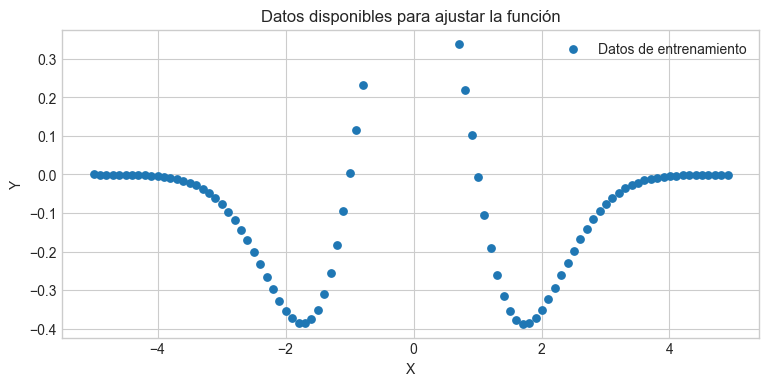

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(X[:, 0], y[:, 0], s=28, color="tab:blue", label="Datos de entrenamiento")
ax.set(xlabel="X", ylabel="Y", title="Datos disponibles para ajustar la función")
ax.legend()
plt.show()

## 2. Red neuronal implementada desde cero

La red calcula

$$\hat{y} = \mathbf{a}_1\mathbf{W}_2 + \mathbf{b}_2, \qquad
\mathbf{a}_1 = \tanh(\mathbf{X}\mathbf{W}_1 + \mathbf{b}_1).$$

Respecto al ejemplo de clasificación, el cambio principal es que la salida es **lineal**: en regresión no interesa limitar la predicción al intervalo $[0,1]$ ni aplicar un umbral. La función de coste es el error cuadrático medio (MSE).

Se normalizan internamente entradas y objetivos para que sus escalas no dificulten el descenso del gradiente. Los parámetros se actualizan con Adam, programado también con operaciones de NumPy. La clase permite variar el número de neuronas, la tasa de aprendizaje, el número de épocas, la regularización y la semilla.

In [4]:
class TwoLayersPerceptron:
    def __init__(
        self,
        input_size,
        hidden_size=12,
        output_size=1,
        learning_rate=0.005,
        epochs=30_000,
        l2=0.0,
        seed=3,
    ):
        if min(input_size, hidden_size, output_size, epochs) <= 0:
            raise ValueError("Los tamaños de las capas y el número de épocas deben ser positivos")
        if learning_rate <= 0 or l2 < 0:
            raise ValueError("learning_rate debe ser positivo y l2 no puede ser negativo")

        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.l2 = l2
        self.seed = seed
        self._initialize_parameters()

    def _initialize_parameters(self):
        rng = np.random.default_rng(self.seed)

        # Xavier mantiene una escala razonable al atravesar la tangente hiperbólica.
        limit_1 = np.sqrt(6 / (self.input_size + self.hidden_size))
        limit_2 = np.sqrt(6 / (self.hidden_size + self.output_size))
        self.W1 = rng.uniform(-limit_1, limit_1, (self.input_size, self.hidden_size))
        self.b1 = np.zeros((1, self.hidden_size))
        self.W2 = rng.uniform(-limit_2, limit_2, (self.hidden_size, self.output_size))
        self.b2 = np.zeros((1, self.output_size))

    @staticmethod
    def _as_matrix(values, expected_columns, name):
        values = np.asarray(values, dtype=float)
        if values.ndim == 1:
            values = values.reshape(-1, 1)
        if values.ndim != 2 or values.shape[1] != expected_columns:
            raise ValueError(f"{name} debe tener {expected_columns} columna(s)")
        if not np.isfinite(values).all():
            raise ValueError(f"{name} contiene valores no finitos")
        return values

    def _forward(self, X):
        z1 = X @ self.W1 + self.b1
        a1 = np.tanh(z1)
        output = a1 @ self.W2 + self.b2  # Salida lineal para regresión.
        return a1, output

    def fit(self, X, y, verbose=False, print_every=2_500):
        X = self._as_matrix(X, self.input_size, "X")
        y = self._as_matrix(y, self.output_size, "y")
        if len(X) != len(y):
            raise ValueError("X e y deben contener el mismo número de ejemplos")
        if print_every <= 0:
            raise ValueError("print_every debe ser positivo")

        # La normalización se aprende solo de los datos recibidos en fit.
        self.X_mean_ = X.mean(axis=0, keepdims=True)
        self.X_std_ = X.std(axis=0, keepdims=True)
        self.y_mean_ = y.mean(axis=0, keepdims=True)
        self.y_std_ = y.std(axis=0, keepdims=True)
        self.X_std_[self.X_std_ == 0] = 1.0
        self.y_std_[self.y_std_ == 0] = 1.0
        X_scaled = (X - self.X_mean_) / self.X_std_
        y_scaled = (y - self.y_mean_) / self.y_std_

        parameters = [self.W1, self.b1, self.W2, self.b2]
        first_moment = [np.zeros_like(parameter) for parameter in parameters]
        second_moment = [np.zeros_like(parameter) for parameter in parameters]
        beta_1, beta_2, epsilon = 0.9, 0.999, 1e-8
        self.history_ = []
        best_loss = np.inf
        best_parameters = None
        n_values = y_scaled.size

        for epoch in range(1, self.epochs + 1):
            # Propagación hacia delante y MSE expresado en las unidades originales.
            hidden, output = self._forward(X_scaled)
            error = output - y_scaled
            mse = np.mean((error * self.y_std_) ** 2)
            self.history_.append(float(mse))

            if mse < best_loss:
                best_loss = mse
                best_parameters = [parameter.copy() for parameter in parameters]

            # Gradientes obtenidos aplicando la regla de la cadena.
            d_output = 2 * error / n_values
            dW2 = hidden.T @ d_output + self.l2 * self.W2
            db2 = np.sum(d_output, axis=0, keepdims=True)
            d_hidden = (d_output @ self.W2.T) * (1 - hidden**2)
            dW1 = X_scaled.T @ d_hidden + self.l2 * self.W1
            db1 = np.sum(d_hidden, axis=0, keepdims=True)
            gradients = [dW1, db1, dW2, db2]

            # Actualización Adam, incluida aquí para no depender de otro framework.
            for index, (parameter, gradient) in enumerate(zip(parameters, gradients)):
                first_moment[index] = beta_1 * first_moment[index] + (1 - beta_1) * gradient
                second_moment[index] = beta_2 * second_moment[index] + (1 - beta_2) * gradient**2
                m_corrected = first_moment[index] / (1 - beta_1**epoch)
                v_corrected = second_moment[index] / (1 - beta_2**epoch)
                parameter -= self.learning_rate * m_corrected / (np.sqrt(v_corrected) + epsilon)

            if verbose and (epoch == 1 or epoch % print_every == 0):
                print(f"Época {epoch:>5}: MSE = {mse:.10f}")

        self.W1, self.b1, self.W2, self.b2 = best_parameters
        self.best_loss_ = best_loss
        self.is_fitted_ = True
        return self

    def predict(self, X):
        if not getattr(self, "is_fitted_", False):
            raise RuntimeError("El modelo debe entrenarse antes de predecir")
        X = self._as_matrix(X, self.input_size, "X")
        X_scaled = (X - self.X_mean_) / self.X_std_
        _, prediction_scaled = self._forward(X_scaled)
        return prediction_scaled * self.y_std_ + self.y_mean_

## 3. Entrenamiento determinista

Se utilizan 12 neuronas ocultas: son suficientes para reproducir la forma suave observada sin aumentar innecesariamente la complejidad. Como el archivo entregado contiene pocos ejemplos y no incluye un conjunto de validación independiente, el ajuste final aprovecha todas las observaciones.

La semilla queda indicada explícitamente. Además, la clase conserva los parámetros de la época con menor error, por lo que una oscilación final del optimizador no empeora el modelo devuelto.

In [5]:
model = TwoLayersPerceptron(
    input_size=X.shape[1],
    hidden_size=12,
    output_size=y.shape[1],
    learning_rate=0.005,
    epochs=30_000,
    l2=0.0,
    seed=3,
)
model.fit(X, y, verbose=True, print_every=5_000)

Época     1: MSE = 0.0250123533


Época  5000: MSE = 0.0000018768


Época 10000: MSE = 0.0000002320


Época 15000: MSE = 0.0000002654


Época 20000: MSE = 0.0000001792


Época 25000: MSE = 0.0000001673


Época 30000: MSE = 0.0000001595


## 4. Monitorización del error

El MSE se guarda tras cada propagación hacia delante en `history_`. La escala logarítmica permite observar tanto la mejora inicial como los cambios pequeños de las últimas épocas.

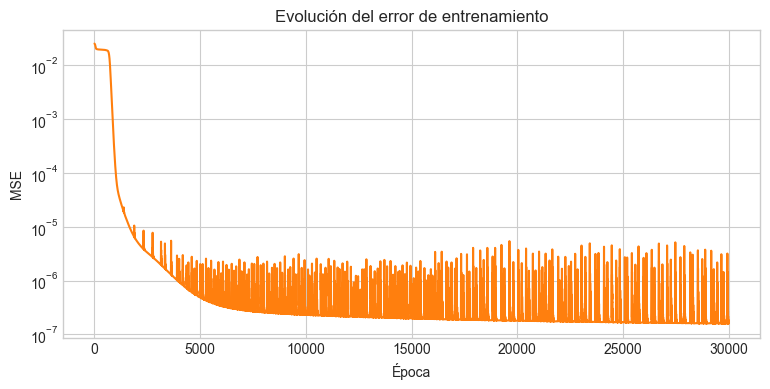

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, len(model.history_) + 1), model.history_, color="tab:orange")
ax.set_yscale("log")
ax.set(xlabel="Época", ylabel="MSE", title="Evolución del error de entrenamiento")
plt.show()

## 5. Calidad del ajuste

Se calculan tres medidas sin recurrir a bibliotecas de aprendizaje automático:

- **MSE**: promedio del error al cuadrado.
- **RMSE**: raíz del MSE, expresada en las mismas unidades que `Y`.
- **$R^2$**: proporción de variabilidad explicada por el modelo.

También se evalúa la red sobre una malla densa. La curva en la zona sin puntos es una interpolación aprendida por la red, no información añadida al entrenamiento.

Mejor MSE de entrenamiento: 1.5861722200e-07
RMSE de entrenamiento:       3.9826777675e-04
R² de entrenamiento:         0.9999936513


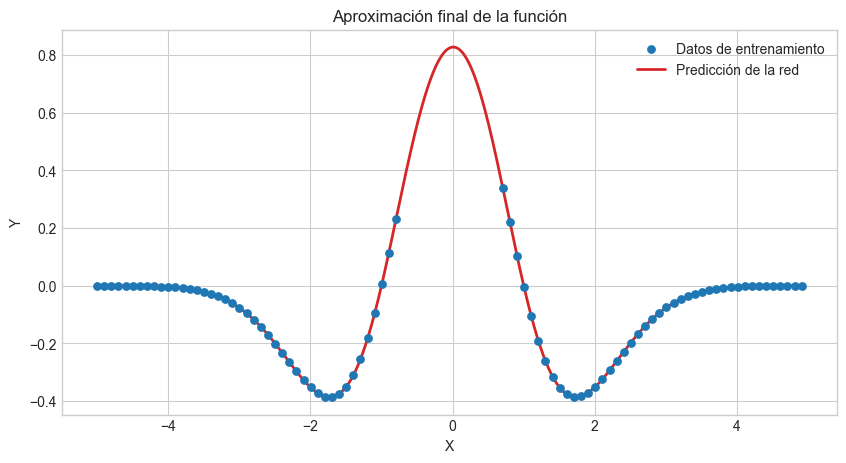

In [7]:
y_pred = model.predict(X)
mse = np.mean((y - y_pred) ** 2)
rmse = np.sqrt(mse)
r2 = 1 - np.sum((y - y_pred) ** 2) / np.sum((y - y.mean(axis=0)) ** 2)

X_grid = np.linspace(X.min(), X.max(), 1_000).reshape(-1, 1)
y_grid = model.predict(X_grid)

print(f"Mejor MSE de entrenamiento: {mse:.10e}")
print(f"RMSE de entrenamiento:       {rmse:.10e}")
print(f"R² de entrenamiento:         {r2:.10f}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(X[:, 0], y[:, 0], s=28, color="tab:blue", label="Datos de entrenamiento", zorder=3)
ax.plot(X_grid[:, 0], y_grid[:, 0], color="tab:red", linewidth=2, label="Predicción de la red")
ax.set(xlabel="X", ylabel="Y", title="Aproximación final de la función")
ax.legend()
plt.show()

## Conclusión

La salida lineal y el MSE convierten el clasificador de referencia en un modelo de regresión. La normalización y Adam hacen estable el entrenamiento, mientras que la semilla local y el uso de operaciones deterministas permiten repetir exactamente el experimento.

La red obtenida sigue de forma continua los datos disponibles y conserva una arquitectura pequeña. Conviene recordar que, al no haber observaciones en parte del intervalo central, la forma concreta de la curva en esa región depende del sesgo de suavidad de la red y debe interpretarse como una interpolación.